In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

In [ ]:
# Load the dataset
df = pd.read_csv("electricity_bill_dataset-selected-columns.csv")

# Display dataset overview
print("Shape of dataset:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Shape of dataset: (1000, 12)

First 5 rows:


,Fan,Refrigerator,AirConditioner,Television,Monitor,MotorPump,Month,City,Company,MonthlyHours,Units,MonthlyBill
0,254.8,600,60,171.3,171.6,38.6,10,Delhi,Torrent Power,720,265.7,1797.28
1,462.3,720,60,197.3,241.6,43.4,4,Kolkata,BESCOM,720,323.6,2161.50
2,383.5,720,240,82.6,228.0,66.3,11,Ahmedabad,Tata Power,720,590.4,3891.86
3,335.5,720,60,161.2,46.2,35.4,7,Chennai,CESC,720,277.6,1861.59
4,176.2,720,60,150.1,44.8,67.2,9,Delhi,Torrent Power,720,279.4,1881.89


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Fan             1000 non-null   float64
 1   Refrigerator    1000 non-null   int64  
 2   AirConditioner  1000 non-null   int64  
 3   Television      1000 non-null   float64
 4   Monitor         1000 non-null   float64
 5   MotorPump       1000 non-null   float64
 6   Month           1000 non-null   int64  
 7   City            1000 non-null   object 
 8   Company         1000 non-null   object 
 9   MonthlyHours    1000 non-null   int64  
 10  Units           1000 non-null   float64
 11  MonthlyBill     1000 non-null   float64
dtypes: float64(6), int64(4), object(2)
memory usage: 93.9+ KB


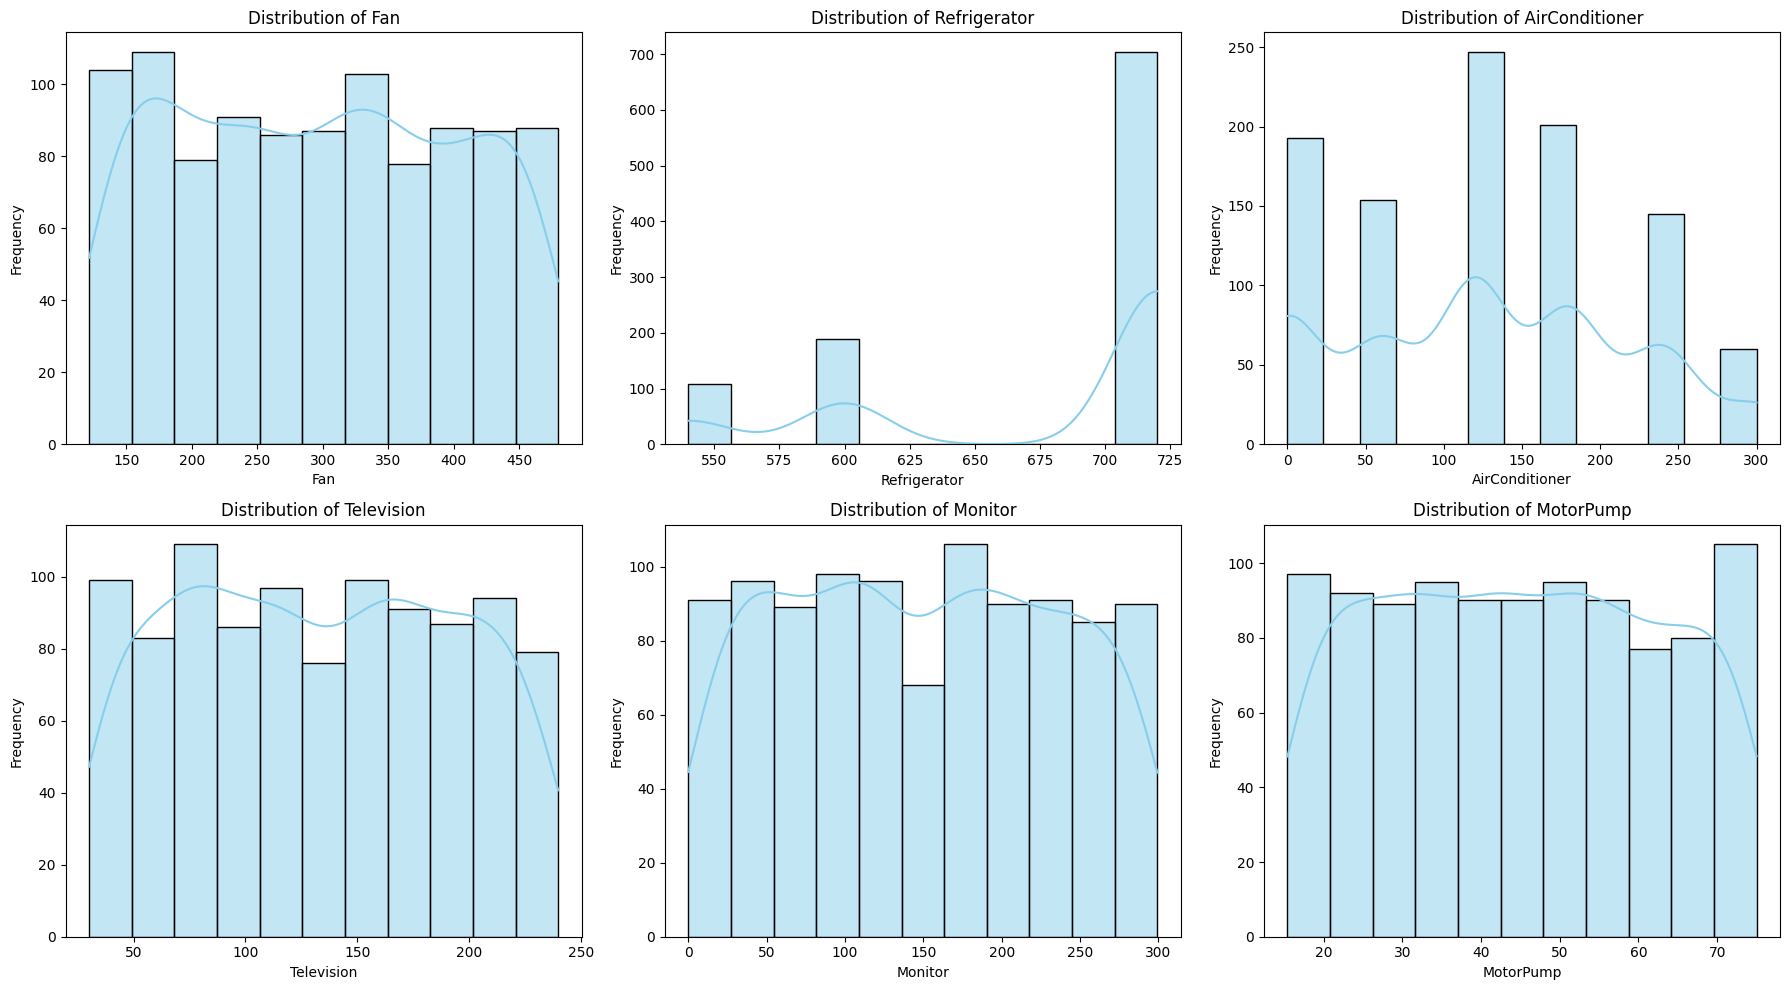

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Explanation of Numerical Feature Distributions for ML Engineers

These histograms show the distribution of each appliance's usage hours (`Fan`, `Refrigerator`, `AirConditioner`, `Television`, `Monitor`, `MotorPump`). As an ML engineer, here's what to look for and consider:

*   **Shape of Distribution (Skewness)**: Observe if the data is symmetrically distributed (bell-shaped), skewed to the left (negative skew), or skewed to the right (positive skew). For example, if a feature like `AirConditioner` usage is heavily skewed to the right, it means most households use it for fewer hours, with a few using it for many hours. Highly skewed features might benefit from **log transformations** or other **power transformations** before being fed into models that assume normally distributed data (e.g., Linear Regression). Random Forest, being tree-based, is less sensitive to feature distributions.

*   **Modality**: Is the distribution unimodal (one peak) or multimodal (multiple peaks)? Multiple peaks could indicate distinct subgroups within your data that might need to be treated differently or explored further (e.g., different user behaviors).

*   **Outliers**: Long tails or isolated bars far from the main distribution might indicate outliers. For instance, a few data points showing extremely high `MotorPump` usage could be genuine or erroneous. Outliers can heavily influence model training, especially for distance-based algorithms or linear models. Strategies for handling outliers include **winsorization**, **trimming**, or using **robust models**.

*   **Range and Scale**: Notice the range of values for each feature. Features with vastly different scales (e.g., `Fan` usage ranging from 0-500 hours vs. `Refrigerator` usage ranging from 500-720 hours) might require **feature scaling** (e.g., Standardization or Min-Max Scaling) for models sensitive to scale, such as SVMs, k-NN, or neural networks. Linear Regression can also benefit from scaling to improve convergence.

*   **Feature Engineering Potential**: If a feature has a very distinct distribution, it might inspire new feature creations. For example, if `AirConditioner` usage shows distinct clusters, you might create a categorical feature indicating 'low usage', 'medium usage', 'high usage'.

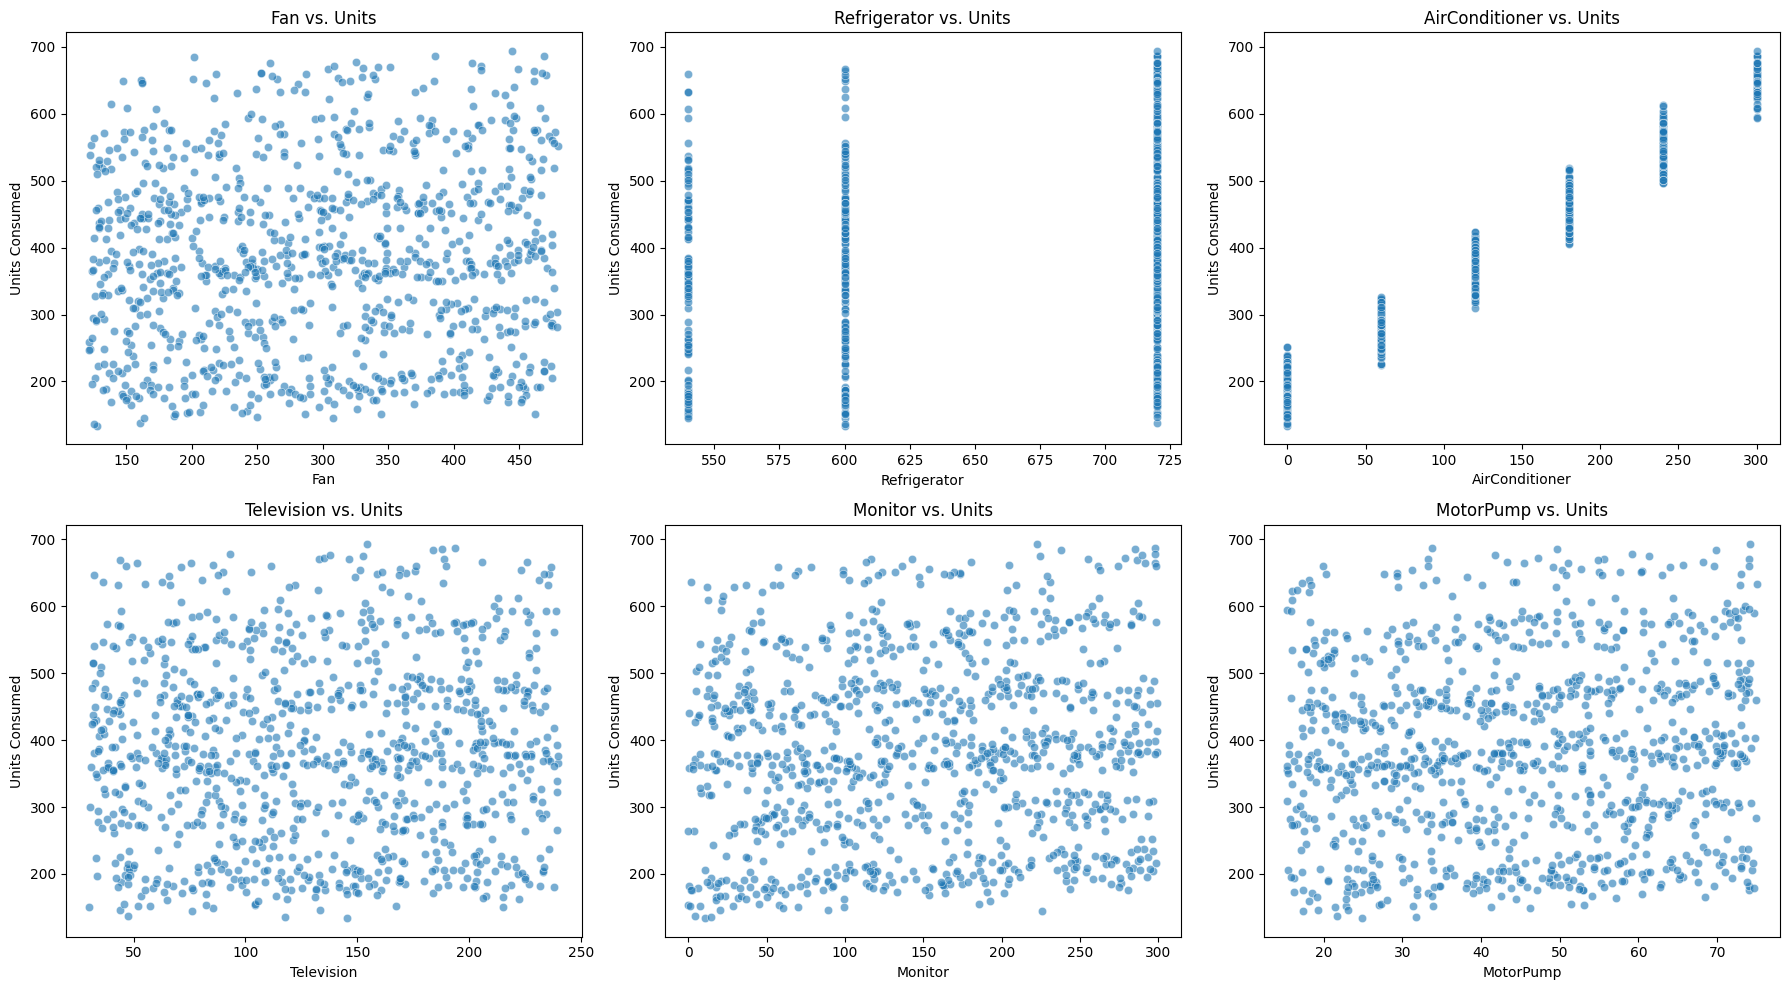

In [ ]:
# Visualize relationships between features and 'Units' (electricity consumption)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.scatterplot(x=df[col], y=df['Units'], ax=axes[i], alpha=0.6)
    axes[i].set_title(f'{col} vs. Units')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Units Consumed')

plt.tight_layout()
plt.show()

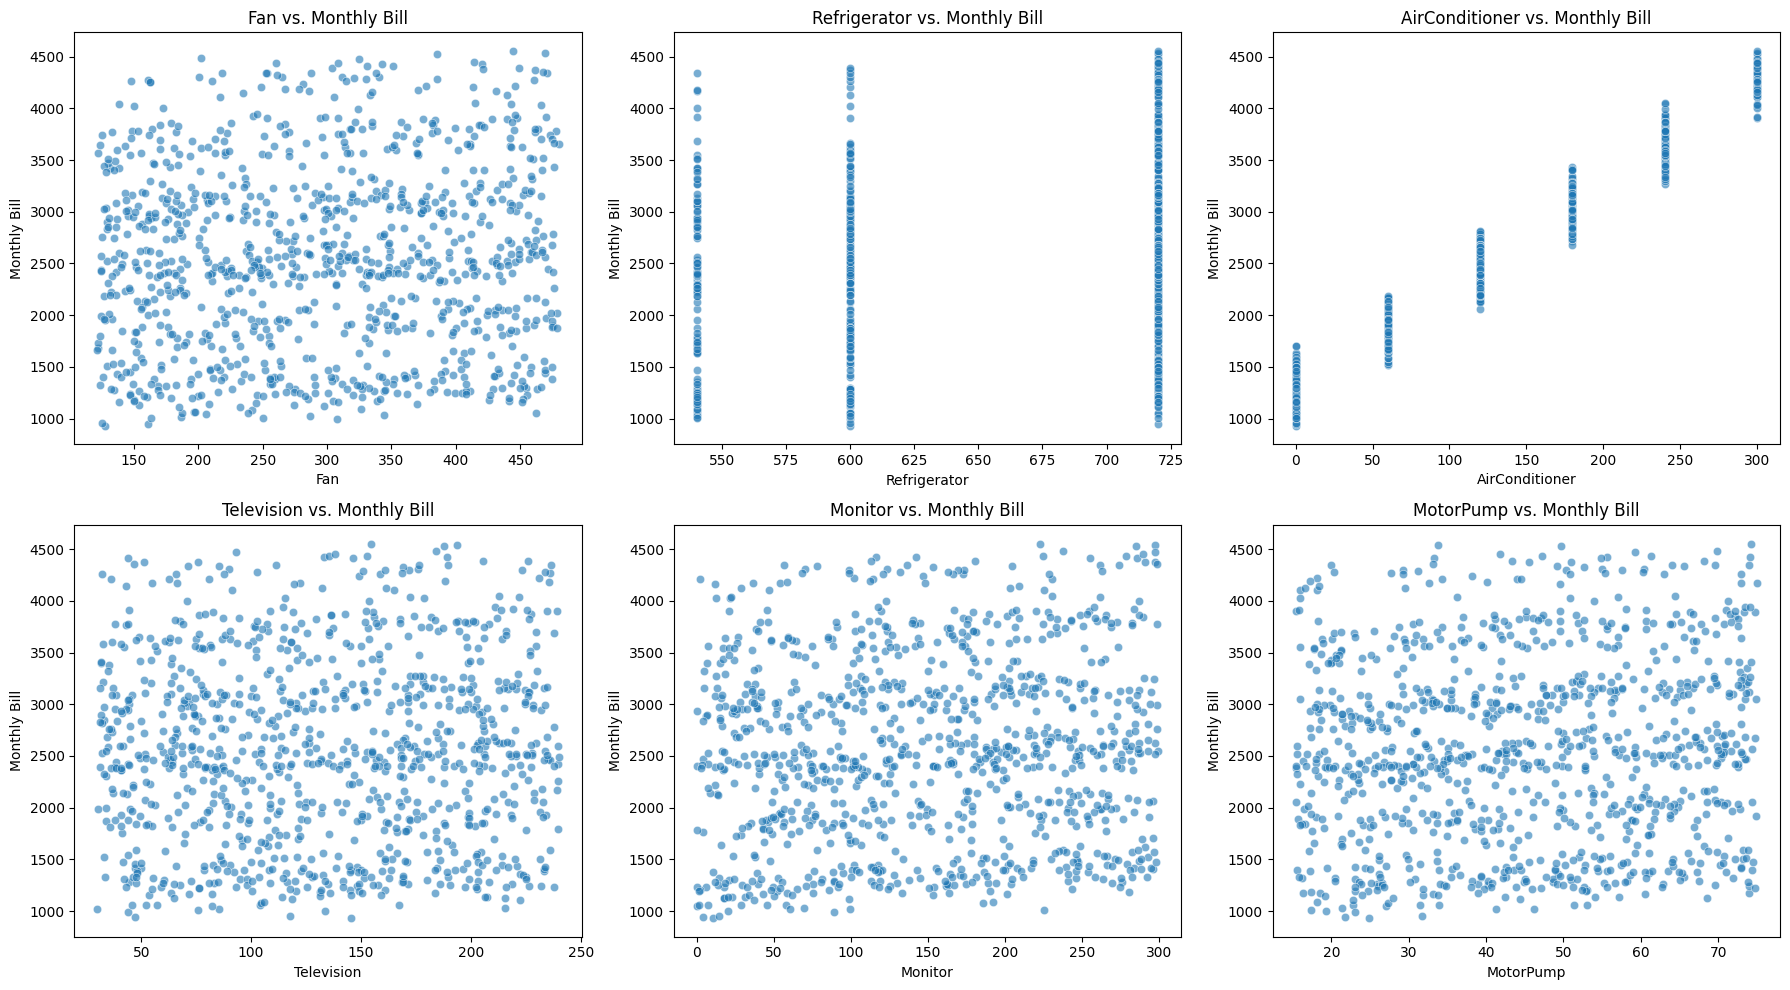

In [ ]:
# Visualize relationships between features and 'MonthlyBill'
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.scatterplot(x=df[col], y=df['MonthlyBill'], ax=axes[i], alpha=0.6)
    axes[i].set_title(f'{col} vs. Monthly Bill')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Monthly Bill')

plt.tight_layout()
plt.show()

### Explanation of Feature-Target Relationships for ML Engineers

These scatter plots illustrate the relationship between each appliance's usage hours and the target variables (`Units` and `MonthlyBill`). For an ML engineer, these plots are crucial for:

*   **Identifying Linear Relationships**: A clear linear trend (either positive or negative) suggests that the feature is a good candidate for linear models. For instance, if `Fan` usage increases linearly with `Units`, a Linear Regression model will likely capture this relationship well.

*   **Identifying Non-Linear Relationships**: If the relationship curves or shows a more complex pattern, non-linear models (like Random Forest, Gradient Boosting, or neural networks) might be more appropriate. Alternatively, **feature engineering** (e.g., creating polynomial features or interaction terms) can help linear models capture these non-linearities.

*   **Strength and Direction of Correlation**: A tight cluster of points around a line indicates a strong correlation, meaning the feature is a good predictor. Scattered points suggest a weak or no correlation. A positive slope means an increase in the feature leads to an increase in the target, and vice-versa for a negative slope.

*   **Homoscedasticity vs. Heteroscedasticity**: Observe if the spread of residuals (the vertical distance of points from an imaginary trend line) is constant across the range of the feature (homoscedasticity) or if it changes (heteroscedasticity). Heteroscedasticity can violate assumptions of some linear models and might require data transformations or robust regression techniques.

*   **Outliers/Influential Points**: Points far away from the general trend can be outliers or influential points. These can disproportionately affect the regression line. Investigating these points is important to understand if they are data errors or represent unique cases.

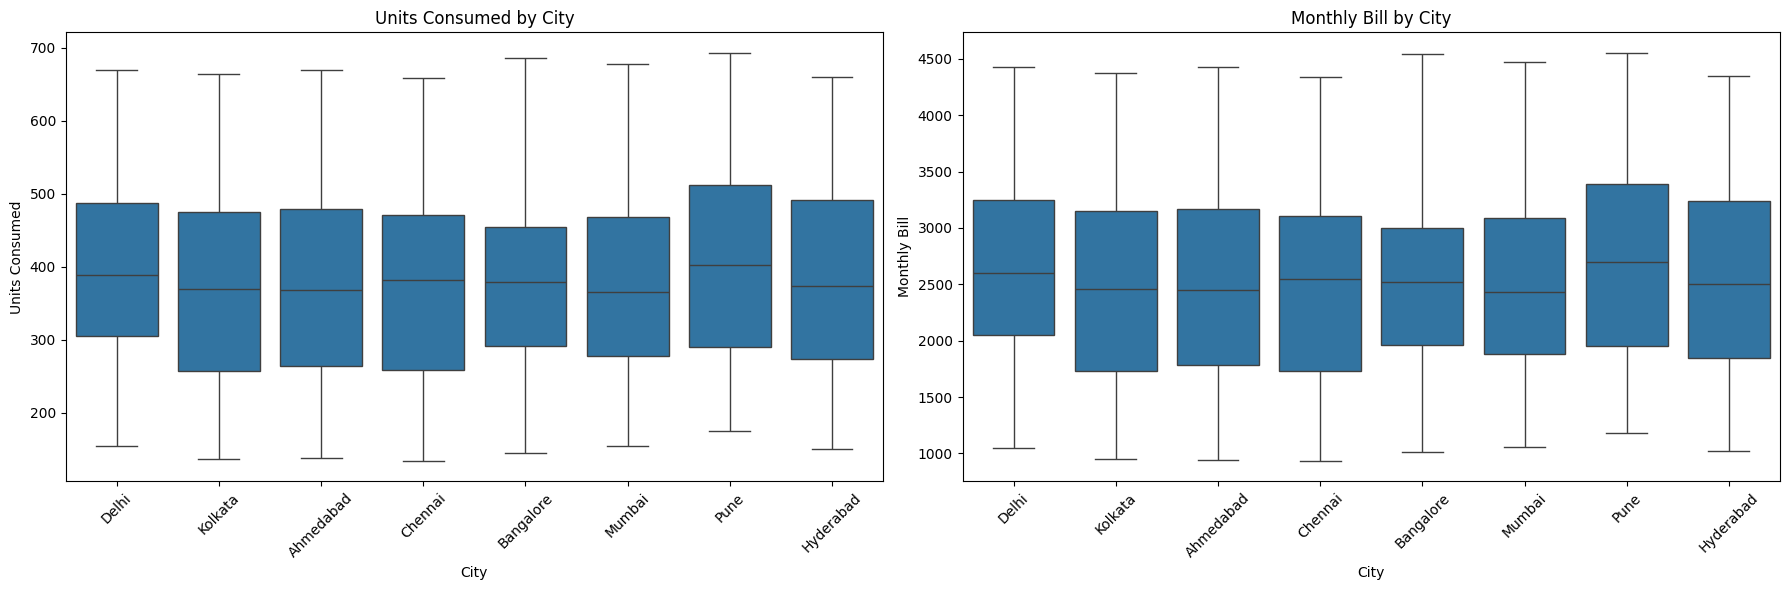

In [ ]:
# Visualize categorical features (City and Company) vs. Units and MonthlyBill

# City vs. Units and MonthlyBill
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

sns.boxplot(x='City', y='Units', data=df, ax=axes[0])
axes[0].set_title('Units Consumed by City')
axes[0].set_xlabel('City')
axes[0].set_ylabel('Units Consumed')
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(x='City', y='MonthlyBill', data=df, ax=axes[1])
axes[1].set_title('Monthly Bill by City')
axes[1].set_xlabel('City')
axes[1].set_ylabel('Monthly Bill')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

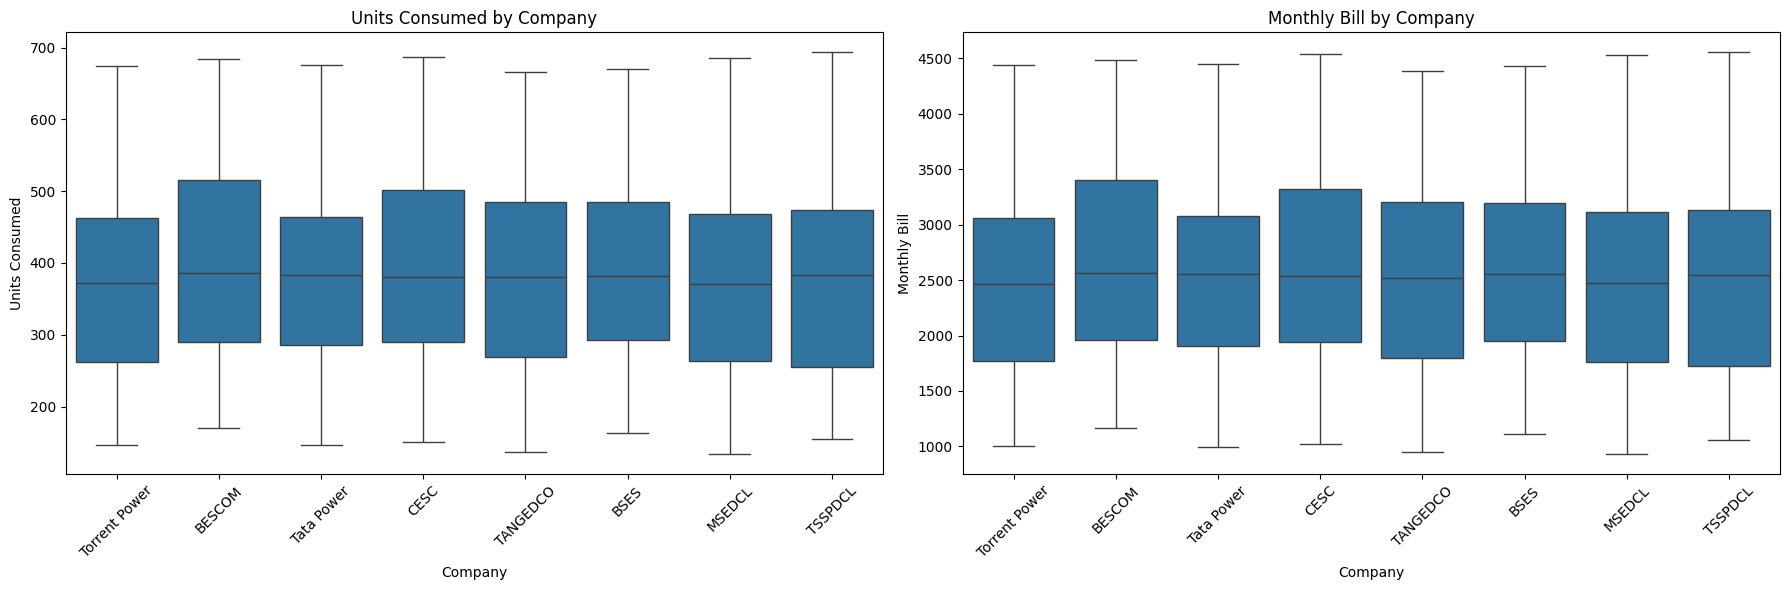

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

sns.boxplot(x='Company', y='Units', data=df, ax=axes[0])
axes[0].set_title('Units Consumed by Company')
axes[0].set_xlabel('Company')
axes[0].set_ylabel('Units Consumed')
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(x='Company', y='MonthlyBill', data=df, ax=axes[1])
axes[1].set_title('Monthly Bill by Company')
axes[1].set_xlabel('Company')
axes[1].set_ylabel('Monthly Bill')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Explanation of Categorical Feature Relationships for ML Engineers

These box plots show the distribution of `Units` and `MonthlyBill` across different `City` and `Company` categories. As an ML engineer, these visualizations help you:

*   **Assess Feature Importance**: If there's a significant difference in the median or spread of `Units`/`MonthlyBill` across different categories (e.g., one city consistently has higher bills than another), then `City` or `Company` is likely an important predictive feature. If the boxes largely overlap, the feature might have less predictive power on its own.

*   **Identify Group-Specific Patterns**: Observe if certain cities or companies have a wider range of bills or more outliers. This could suggest different consumption patterns or pricing structures specific to those groups.

*   **Encoding Strategies**: Categorical features cannot be directly used by most machine learning models and need to be encoded. Based on the insights from these plots:
    *   **One-Hot Encoding**: If there are many distinct categories with significant differences, one-hot encoding is a common approach. However, if there are too many categories (high cardinality), it can lead to a very sparse dataset and increase dimensionality.
    *   **Target Encoding / Mean Encoding**: If a category strongly correlates with the target variable, you might consider encoding it by replacing the category with the mean target value for that category. This can capture the relationship effectively.
    *   **Feature Grouping**: If several categories show similar distributions, they could potentially be grouped together to reduce cardinality.

*   **Potential for Interaction Terms**: Differences observed across categories might suggest that the effect of numerical features could also vary by category (e.g., `Fan` usage might have a different impact on bill in `City A` vs. `City B`). This hints at the potential benefit of creating interaction features.

In [ ]:
feature_cols = ['Fan', 'Refrigerator', 'AirConditioner', 'Television', 'Monitor', 'MotorPump']

X = df[feature_cols]
y_units = df['Units']
y_bill = df['MonthlyBill']

# 80-20 Train-Test split
X_train, X_test, y_units_train, y_units_test, y_bill_train, y_bill_test = train_test_split(
    X, y_units, y_bill, test_size=0.2, random_state=42
)

print(f"Training set samples: {len(X_train)}")
print(f"Testing set samples:  {len(X_test)}")

Training set samples: 800
Testing set samples:  200


In [ ]:
# Model 1: Linear Regression
lr_units = LinearRegression()
lr_units.fit(X_train, y_units_train)

lr_bill = LinearRegression()
lr_bill.fit(X_train, y_bill_train)

# Model 2: Random Forest Regressor
rf_units = RandomForestRegressor(n_estimators=100, random_state=42)
rf_units.fit(X_train, y_units_train)

rf_bill = RandomForestRegressor(n_estimators=100, random_state=42)
rf_bill.fit(X_train, y_bill_train)

print("Both models trained successfully!")

Both models trained successfully!


In [ ]:
def evaluate(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {'Model': name, 'R2 Score': f"{r2:.4f}", 'MAE': f"{mae:.2f}", 'RMSE': f"{rmse:.2f}"}

eval_results = []
eval_results.append(evaluate('Linear Regression (Units)', y_units_test, lr_units.predict(X_test)))
eval_results.append(evaluate('Random Forest (Units)', y_units_test, rf_units.predict(X_test)))
eval_results.append(evaluate('Linear Regression (Bill)', y_bill_test, lr_bill.predict(X_test)))
eval_results.append(evaluate('Random Forest (Bill)', y_bill_test, rf_bill.predict(X_test)))

results_df = pd.DataFrame(eval_results)
print("\n--- Model Performance Comparison ---")
display(results_df)


--- Model Performance Comparison ---


,Model,R2 Score,MAE,RMSE
0,Linear Regression (Units),0.9984,4.30,5.43
1,Random Forest (Units),0.9941,8.11,10.44
2,Linear Regression (Bill),0.9982,30.09,37.48
3,Random Forest (Bill),0.9941,52.64,67.96


In [ ]:
model_artifact = {
    'model_units': rf_units,
    'model_bill': rf_bill,
    'feature_cols': feature_cols,
    'appliance_labels': {
        'Fans': 'Fans (hours/month)',
        'Refrigerator': 'Refrigerator (hours/month)',
        'AirConditioner': 'Air Conditioner (hours/month)',
        'Television': 'Television (hours/month)',
        'Monitor': 'Monitor / PC (hours/month)',
        'MotorPump': 'Water Motor Pump (hours/month)'
    },
    'r2_units': r2_score(y_units_test, rf_units.predict(X_test)),
    'r2_bill': r2_score(y_bill_test, rf_bill.predict(X_test))
}

export_file = 'model.pkl'
joblib.dump(model_artifact, export_file)
print(f"Model successfully serialized and saved to '{export_file}'.")

Model successfully serialized and saved to 'model.pkl'.
